# CA1 – Machine Learning
## Predicting Maternal Health Risk during Pregnancy

- **Student:** Daniella Silveira e Silva
- **Programme:** HDip in Science in Data Analytics for Business – CCT College Dublin
- **Module:** Machine Learning | **Lecturer:** Dr. Muhammad Iqbal
- **GitHub:** https://github.com/Daniella-CCT/Machine-Learning-Sept26
- **Dataset:** Maternal Health Risk (Ahmed, 2020), UCI Machine Learning Repository – https://archive.ics.uci.edu/dataset/863/maternal+health+risk

This notebook follows the six phases of the **CRISP-DM** methodology (Larose and Larose, 2014): business understanding, data understanding, data preparation, modelling, evaluation and deployment (section 8). All models were built with scikit-learn (Pedregosa et al., 2011).

In [1]:
# ===== Libraries =====
import pandas as pd                 # data handling
import matplotlib.pyplot as plt     # charts
import seaborn as sns               # statistical charts
from scipy import stats             # statistical tests

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

import warnings
warnings.filterwarnings("ignore")   # hide library warnings to keep the output clean

RANDOM_STATE = 42                   # fixed seed, so the results can be reproduced
sns.set_style("whitegrid")
COLORS = {"low risk": "#4C9F70", "mid risk": "#F2B134", "high risk": "#D1495B"}

## 1. Business understanding

In 2023, about 260,000 women died from complications of pregnancy and childbirth, and most of these deaths were preventable (WHO, 2025). High blood pressure during pregnancy (pre-eclampsia and eclampsia) is one of the main causes. Early identification of high-risk pregnancies helps health workers decide which women need care first, especially in rural areas where women do not see a doctor often.

**Goal:** build classification models that predict the **risk level** of a pregnant woman (low, mid or high) from six vital signs, and find out which signs matter most.

**Questions for this project:**
1. Which features are the most important for predicting the maternal risk level?
2. Which classifier is more suitable for this problem – Random Forest or Support Vector Machine (SVM) – and why?
3. How do the size of the test split and hyperparameter tuning affect accuracy and generalisation?

## 2. Data understanding
### 2.1 Load and describe the dataset

The data was collected from hospitals and community clinics in rural Bangladesh through an IoT-based risk monitoring system (Ahmed et al., 2020). Each row is one pregnant woman.

| Column | Description | Unit |
|---|---|---|
| Age | Age of the woman during pregnancy | years |
| SystolicBP | Upper value of the blood pressure | mmHg |
| DiastolicBP | Lower value of the blood pressure | mmHg |
| BS | Blood sugar (glucose) level | mmol/L |
| BodyTemp | Body temperature | °F |
| HeartRate | Resting heart rate | beats per minute |
| **RiskLevel** | **Target:** risk level during pregnancy | low / mid / high risk |

In [2]:
# Load the dataset (the CSV file must be in the same folder as this notebook)
df = pd.read_csv("maternal_health_risk.csv")

print("Number of rows and columns:", df.shape)
df.head()

Number of rows and columns: (1014, 7)


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk


In [3]:
# Data types and missing values
df.info()
print("\nMissing values per column:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          1014 non-null   int64  
 1   SystolicBP   1014 non-null   int64  
 2   DiastolicBP  1014 non-null   int64  
 3   BS           1014 non-null   float64
 4   BodyTemp     1014 non-null   float64
 5   HeartRate    1014 non-null   int64  
 6   RiskLevel    1014 non-null   object 
dtypes: float64(2), int64(4), object(1)
memory usage: 55.6+ KB

Missing values per column:
Age            0
SystolicBP     0
DiastolicBP    0
BS             0
BodyTemp       0
HeartRate      0
RiskLevel      0
dtype: int64


In [4]:
# Summary statistics of the six features
df.describe().round(2)

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate
count,1014.00,1014.0,1014.00,1014.00,1014.00,1014.00
mean,29.87,113.2,76.46,8.73,98.67,74.30
std,13.47,18.4,13.89,3.29,1.37,8.09
min,10.00,70.0,49.00,6.00,98.00,7.00
25%,19.00,100.0,65.00,6.90,98.00,70.00
50%,26.00,120.0,80.00,7.50,98.00,76.00
75%,39.00,120.0,90.00,8.00,98.00,80.00
max,70.00,160.0,100.00,19.00,103.00,90.00


**Observations**
- There are 1.014 records, 6 numeric features and 1 categorical target. There are **no missing values.**
- Th minimum **HeartRate is 7 bpm**, which is imossible for a living person. This is a recording error.
- **Age** goes from 10 to 70 years. Some of these ages are very unlikely for a pregnancy (see section 3.3).
- **BodyTemp** is 98°F for most women (the 25th, 50th and 75th percentiles are all 98).

### 2.2 Target variable

RiskLevel
low risk     406
mid risk     336
high risk    272
Name: count, dtype: int64


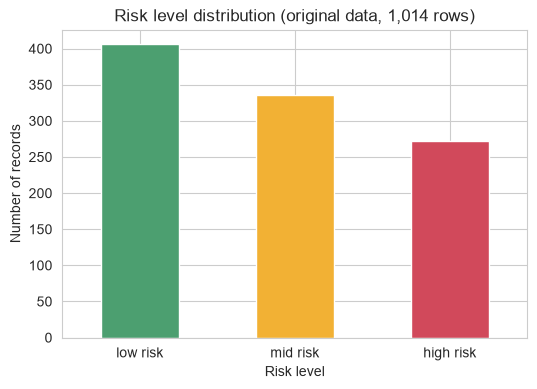

In [5]:
# Distribution of the target variable (risk level)
class_names = ["low risk", "mid risk", "high risk"]
counts = df["RiskLevel"].value_counts()[class_names]
print(counts)

counts.plot(kind="bar", color=[COLORS[c] for c in class_names], figsize=(6, 4))
plt.title(f"Risk level distribution (original data, {len(df):,} rows)")
plt.xlabel("Risk level")
plt.ylabel("Number of records")
plt.xticks(rotation=0)
plt.show()

The classes are not balanced: low risk is the largest group (406 records), followed by mid risk (336) and high risk (272).

### 2.3 Duplicate records

In [6]:
# Count the rows that are exact copies of nother row
n_dup = df.duplicated().sum()
print(f"Exact duplicate rows: {n_dup} of {len(df)} ({n_dup / len(df):.1%})")

Exact duplicate rows: 562 of 1014 (55.4%)


**More than half of the records (55.4%) are exact copies of other records.** If they stay in the data, the same record can appear in both the training set and the test set. The model would then be tested on data it has already seen, and the accuracy would look better than it really is. This problem is called data leakage (Kaufman et al., 2012). Section 3.3 measures this effect.

## 3. Data preparation
### 3.1 Remove impossible values and duplicates

In [7]:
# Step 1: remove records with an impossible heart rate (7 bpm is a recording error)
print("Records with HeartRate below 40 bpm:", (df["HeartRate"] < 40).sum())
df_clean = df[df["HeartRate"] >= 40]

# Step 2: remove exact duplicate rows
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Rows before cleaning:", len(df))
print("Rows after cleaning: ", len(df_clean))
print("\nClass distribution after cleaning:")
print(df_clean["RiskLevel"].value_counts()[class_names])

Records with HeartRate below 40 bpm: 2
Rows before cleaning: 1014
Rows after cleaning:  451

Class distribution after cleaning:
RiskLevel
low risk     233
mid risk     106
high risk    112
Name: count, dtype: int64


After cleaning, **451 records** remain, which is above the minimum of 300 records required for this project. Low risk is now about half of the records (233 of 451).

### 3.2 Features and target
The target is encoded as ordered numbers (low = 0, mid = 1, high = 2). The **majority-class baseline** is the accuracy of a naive model that always predicts "low risk". A useful model must be clearly better than this baseline.

In [8]:
# Features (X) and target (y)
features = ["Age", "SystolicBP", "DiastolicBP", "BS", "BodyTemp", "HeartRate"]
X = df_clean[features]

# Encode the target as ordered numbers: Low = 0, mid = 1, high = 2
risk_map = {"low risk": 0, "mid risk": 1, "high risk": 2}
y = df_clean["RiskLevel"].map(risk_map)

#Accuracy of a naive model that always predict the ost frequent class (baseline)
baseline = y.value_counts(normalize=True).max()
print("X shape:", X.shape, "| y shape:", y.shape)
print(f"Majority-class baseline accuracy: {baseline:.3f}")

X shape: (451, 6) | y shape: (451,)
Majority-class baseline accuracy: 0.517


### 3.3 Data quality checks
Two quick checks with default models and 5-fold cross-validation:
1. **Duplicates:** how the accuracy changes if the duplicate records are kept.
2. **Implausible ages:** 69 records have an age of 10–12 years or over 50 years, which is very unlikely during pregnancy. This check shows if removing them changes the results.

The SVM uses **StandardScaler**, which the lecture notes recommend for SVM, because SVM is based on distances and is sensitive to the scale of the features. RobustScaler was not used because BodyTemp has an interquartile range of zero (most values are 98 °F). Random Forest does not need scaled features.

In [9]:
# 5-fold stratified cross-validation (keeps the class proportions in every fold)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Default models, used in the checks below and in section 5
rf_default = RandomForestClassifier(random_state=RANDOM_STATE)
svm_default = make_pipeline(StandardScaler(), SVC(random_state=RANDOM_STATE))

def cv_accuracy(model, X_data, y_data):
    """Mean accuracy of a model using 5-fold cross-validation."""
    return cross_val_score(model, X_data, y_data, cv=cv, scoring="accuracy").mean()

# Check 1: data WITH the duplicates (only the impossible heart rate removed)
df_dup = df[df["HeartRate"] >= 40]
X_dup, y_dup = df_dup[features], df_dup["RiskLevel"].map(risk_map)

# Check 2: clean data WITHOUT the implausible ages (Age < 13 or Age > 50)
odd_age = (df_clean["Age"] < 13) | (df_clean["Age"] > 50)
print("Records with an implausible age for pregnancy:", odd_age.sum())
X_age, y_age = X[~odd_age], y[~odd_age]

checks = pd.DataFrame({
    "Data version": ["Clean data (used in this project)", "With duplicates", "Without implausible ages"],
    "Rows": [len(X), len(X_dup), len(X_age)],
    "RF accuracy (CV)": [cv_accuracy(rf_default, X, y), cv_accuracy(rf_default, X_dup, y_dup),
                         cv_accuracy(rf_default, X_age, y_age)],
    "SVM accuracy (CV)": [cv_accuracy(svm_default, X, y), cv_accuracy(svm_default, X_dup, y_dup),
                          cv_accuracy(svm_default, X_age, y_age)],
})
checks.round(3)

Records with an implausible age for pregnancy: 69


,Data version,Rows,RF accuracy (CV),SVM accuracy (CV)
0,Clean data (used in this project),451,0.650,0.703
1,With duplicates,1012,0.851,0.698
2,Without implausible ages,382,0.649,0.686


**Results of the checks**
- **With duplicates**, Random Forest reaches an accuracy of 0.851, against 0.650 on the clean data. This higher value is not real: it comes from copies of the same records in the training and validation folds. For this reason, the duplicates were removed.
- **Without the implausible ages**, the accuracy changes very little (Random Forest 0.649 vs 0.650; SVM 0.686 vs 0.703). These records were **kept**, because removing them does not change the conclusions and the dataset gives no information to confirm that they are errors. This is noted as a limitation.

## 4. Feature significance (statistical reasoning)
The boxplots show how each feature changes across the three risk levels.

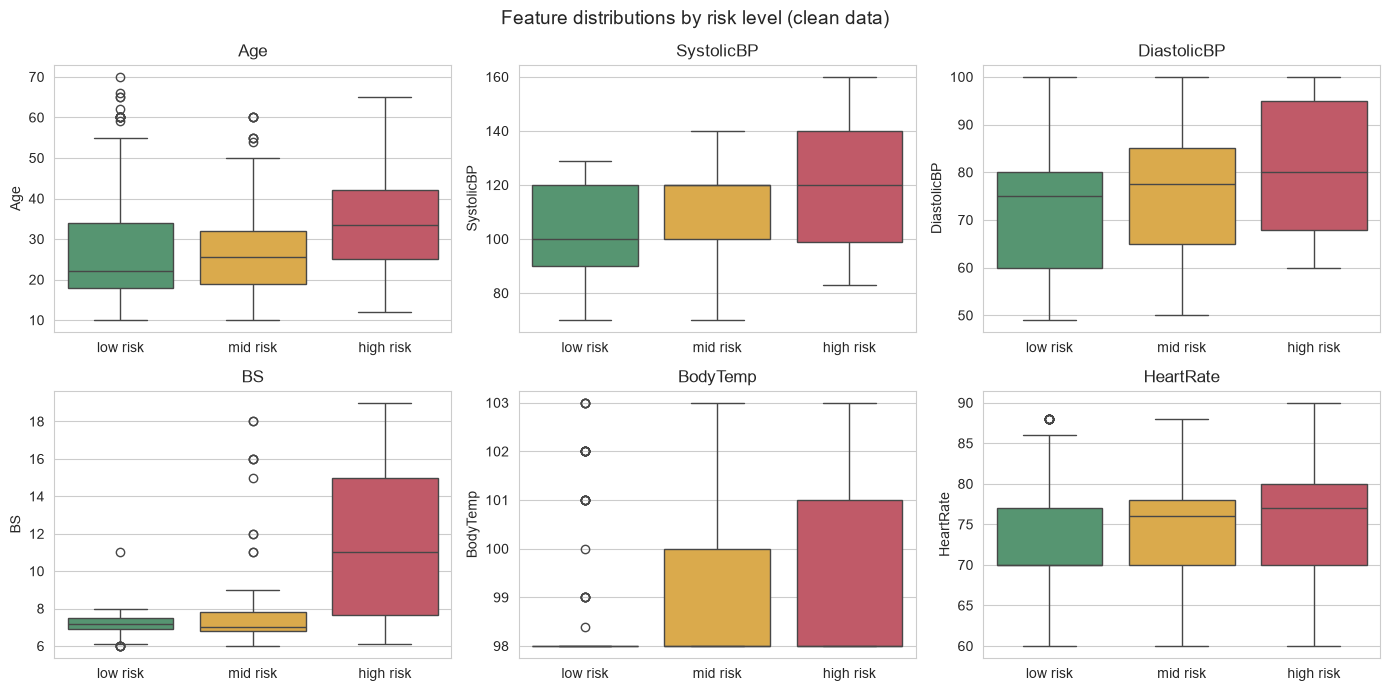

In [10]:
# Boxplots: how each feature changes across the three risk levels
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flatten(), features):
    sns.boxplot(data=df_clean, x="RiskLevel", y=col, order=class_names,
                hue="RiskLevel", hue_order=class_names, dodge=False,
                palette=[COLORS[c] for c in class_names], ax=ax)
    if ax.get_legend() is not None:   # the colours already match the x-axis labels
        ax.get_legend().remove()
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Feature distributions by risk level (clean data)", fontsize=14)
plt.tight_layout()
plt.show()

**Observations:** women with **high risk** have clearly higher blood sugar (BS) and higher blood pressure. Low-risk and mid-risk women have similar values in most features, which suggests that these two classes will be harder to separate.

The correlation matrix checks if some features carry the same information.

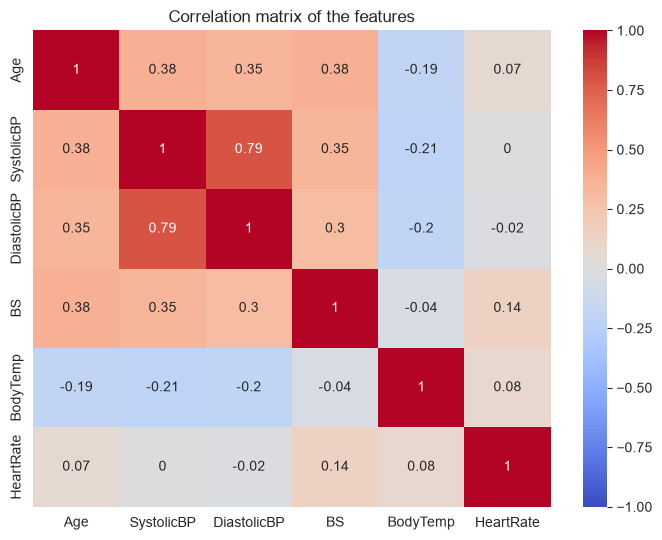

In [11]:
# Correlation between the features (Pearson)
plt.figure(figsize=(7, 5.5))
sns.heatmap(X.corr().round(2), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix of the features")
plt.tight_layout()
plt.show()

Systolic and diastolic blood pressure are strongly correlated (0.79), which is expected. All other correlations are weak or moderate (below 0.4). With only six features and little redundancy, **dimensionality reduction (for example PCA) is not needed** in this project: it would not reduce the complexity in a meaningful way, and it would make the results harder to interpret.

Two statistical tests were used to check if the differences between the risk groups are significant:
- **Kruskal-Wallis H test** (Kruskal and Wallis, 1952): a non-parametric test that compares the three groups without assuming a normal distribution. This is important here because several features are skewed (for example BS and BodyTemp).
- **One-way ANOVA**: compares the group means, as a second check.

Null hypothesis (H0): the feature has the same distribution in the three risk groups. If p < 0.05, H0 is rejected.

In [12]:
# Kruskal-Wallis test (non-parametric) and one-way ANOVA for each feature
# H0: the feature has the same distribution in the three risk groups
rows = []
for col in features:
    groups = [df_clean.loc[df_clean["RiskLevel"] == c, col] for c in class_names]
    h_stat, p_kw = stats.kruskal(*groups)
    f_stat, p_anova = stats.f_oneway(*groups)
    rows.append({"Feature": col, "Kruskal-Wallis H": h_stat, "Kruskal-Wallis p-value": p_kw,
                 "ANOVA F": f_stat, "ANOVA p-value": p_anova})

significance = pd.DataFrame(rows).sort_values("Kruskal-Wallis H", ascending=False)
significance["Significant (p < 0.05)"] = significance["Kruskal-Wallis p-value"] < 0.05
significance.round({"Kruskal-Wallis H": 2, "ANOVA F": 2})

,Feature,Kruskal-Wallis H,Kruskal-Wallis p-value,ANOVA F,ANOVA p-value,Significant (p < 0.05)
3,BS,106.65,6.936817e-24,114.15,8.599894e-41,True
1,SystolicBP,44.78,1.885450e-10,27.15,7.436853e-12,True
4,BodyTemp,31.90,1.183313e-07,16.20,1.609950e-07,True
2,DiastolicBP,25.54,2.849203e-06,16.69,1.021172e-07,True
0,Age,23.16,9.336876e-06,8.53,2.323535e-04,True
5,HeartRate,14.44,7.322151e-04,8.19,3.201951e-04,True


**All six features are significant (p < 0.001 in both tests).** Blood sugar has by far the strongest effect (H = 106.65), followed by systolic blood pressure (H = 44.78). Heart rate has the weakest effect (H = 14.44). Section 7.2 checks if the models give the same ranking.

## 5. Modelling
### 5.1 Choice of models
This is a **supervised multi-class classification** problem, because the target is a category (low, mid or high risk). The dataset is small (451 records), all features are numeric, the classes are not balanced, and the boxplots show that the relation between the features and the risk level is not linear (for example, the risk increases sharply only when blood sugar is very high).

Two models from the module were chosen (Müller and Guido, 2016):
- **Random Forest** (Breiman, 2001) – an ensemble of decision trees that vote for the final class. It learns non-linear relations, does not need scaled features, is robust to outliers and gives feature importance, which helps to answer question 1. The risk is overfitting when the trees are too deep.
- **Support Vector Machine (SVM)** with the RBF kernel (Cortes and Vapnik, 1995) – it finds the boundary with the maximum margin between the classes, and the kernel allows this boundary to be non-linear. SVM works well on small datasets, and its parameters C and gamma control the bias-variance trade-off. It needs scaled features.

**Validation approach**
- The data is split into training and test sets, with **5%, 15% and 25%** of the records held out for testing. The splits are **stratified**, so all sets keep the same class proportions.
- **5-fold stratified cross-validation** is applied to the training set to measure how reliable the accuracy is (mean and standard deviation across the folds).
- The test set is used only once, to measure the accuracy on unseen data.

### 5.2 Accuracy across the three test splits

In [13]:
# Train and evaluate both default models with three test sizes
split_results = []
for test_size in [0.05, 0.15, 0.25]:
    # Stratified split: train and test sets keep the same class proportions
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, stratify=y, random_state=RANDOM_STATE)

    for name, model in [("Random Forest", rf_default), ("SVM", svm_default)]:
        cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")  # CV on training data only
        model.fit(X_train, y_train)
        split_results.append({
            "Test size": f"{int(test_size * 100)}%",
            "Train rows": len(X_train),
            "Test rows": len(X_test),
            "Model": name,
            "CV accuracy (mean)": cv_scores.mean(),
            "CV accuracy (std)": cv_scores.std(),
            "Train accuracy": model.score(X_train, y_train),
            "Test accuracy": model.score(X_test, y_test),
        })

split_df = pd.DataFrame(split_results)
split_df.round(3)

,Test size,Train rows,Test rows,Model,CV accuracy (mean),CV accuracy (std),Train accuracy,Test accuracy
0,5%,428,23,Random Forest,0.643,0.030,0.921,0.696
1,5%,428,23,SVM,0.687,0.026,0.736,0.696
2,15%,383,68,Random Forest,0.661,0.044,0.924,0.706
3,15%,383,68,SVM,0.702,0.042,0.715,0.706
4,25%,338,113,Random Forest,0.651,0.052,0.941,0.664
5,25%,338,113,SVM,0.675,0.038,0.725,0.699


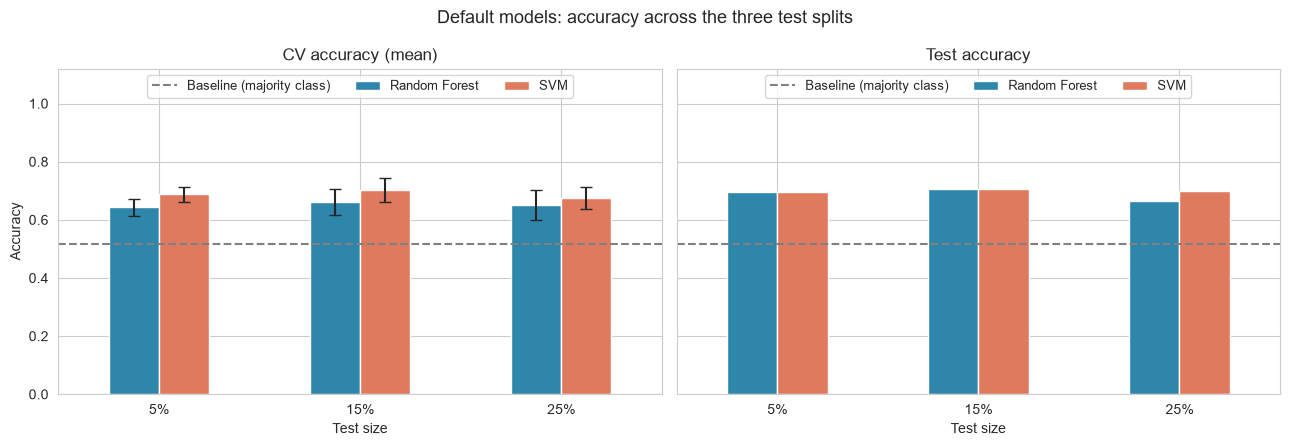

In [14]:
# Chart: cross-validation accuracy (with standard deviation) and test accuracy for each split
order = ["5%", "15%", "25%"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, metric in zip(axes, ["CV accuracy (mean)", "Test accuracy"]):
    values = split_df.pivot(index="Test size", columns="Model", values=metric).loc[order]
    errors = None
    if metric == "CV accuracy (mean)":
        errors = split_df.pivot(index="Test size", columns="Model", values="CV accuracy (std)").loc[order]
    values.plot(kind="bar", yerr=errors, capsize=4, ax=ax, color=["#2E86AB", "#E07A5F"])
    ax.axhline(baseline, color="grey", linestyle="--", label="Baseline (majority class)")
    ax.set_title(metric)
    ax.set_xlabel("Test size")
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0, 1.12)
    ax.tick_params(axis="x", rotation=0)
    ax.legend(loc="upper center", ncol=3, fontsize=9)
plt.suptitle("Default models: accuracy across the three test splits", fontsize=13)
plt.tight_layout()
plt.show()

**Interpretation**
- Both models are clearly better than the baseline (0.517).
- **The cross-validation accuracy is stable across the three splits**: 0.643–0.661 for Random Forest and 0.675–0.702 for SVM. The results do not depend much on the size of the split.
- **The test accuracy changes more** (0.664–0.706), because the test sets are small. The 5% split has only 23 test records, so one error changes the accuracy by about 4 percentage points. This is why cross-validation gives a more reliable estimate than a single test set.
- With default settings, **SVM is more accurate in cross-validation** in all three splits.
- **Random Forest overfits**: its training accuracy (0.92–0.94) is much higher than its cross-validation and test accuracy. The SVM training accuracy (0.72–0.74) is close to its test accuracy, so SVM generalises well.

## 6. Hyperparameter tuning
The main purpose of hyperparameter tuning is to find the settings that give the best performance on **new data**, not on the training data. Good settings keep the balance between underfitting and overfitting.

**GridSearchCV** tests every combination of values in a grid. For each combination, it runs 5-fold cross-validation on the training set and keeps the combination with the highest mean accuracy. The test set is not used during the search, so the final test result is fair.

The **25% split** was chosen for tuning because it has the largest test set (113 records), so its test accuracy is the most reliable of the three splits.

| Model | Hyperparameter | Values tested | What it controls |
|---|---|---|---|
| Random Forest | n_estimators | 100, 200, 300 | number of trees |
| Random Forest | max_depth | None, 5, 10 | maximum depth of each tree (limits overfitting) |
| Random Forest | min_samples_leaf | 1, 2, 4 | minimum records in a leaf (makes the trees smoother) |
| SVM | C | 0.1, 1, 10, 100 | penalty for errors (small C = wider margin, simpler model) |
| SVM | gamma | scale, 0.01, 0.1, 1 | influence of each training point (large gamma = more complex boundary) |

In [15]:
# Hyperparameter tuning on the 25% test split (the largest test set)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

# Random Forest: number of trees, tree depth and minimum records per leaf
rf_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}
rf_search = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE), rf_grid,
                         cv=cv, scoring="accuracy", n_jobs=-1)
rf_search.fit(X_train, y_train)

# SVM: C (penalty for errors) and gamma (influence of each training point)
# The scaler is inside the pipeline, so it is fitted only on the training folds
svm_grid = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": ["scale", 0.01, 0.1, 1],
}
svm_search = GridSearchCV(make_pipeline(StandardScaler(), SVC(random_state=RANDOM_STATE)), svm_grid,
                          cv=cv, scoring="accuracy", n_jobs=-1)
svm_search.fit(X_train, y_train)

print("Combinations tested - Random Forest:", len(rf_search.cv_results_["params"]),
      "| SVM:", len(svm_search.cv_results_["params"]))
print("Random Forest best parameters:", rf_search.best_params_)
print(f"Random Forest best CV accuracy: {rf_search.best_score_:.3f}")
print("SVM best parameters:", svm_search.best_params_)
print(f"SVM best CV accuracy: {svm_search.best_score_:.3f}")

Combinations tested - Random Forest: 27 | SVM: 16
Random Forest best parameters: {'max_depth': 5, 'min_samples_leaf': 2, 'n_estimators': 200}
Random Forest best CV accuracy: 0.716
SVM best parameters: {'svc__C': 100, 'svc__gamma': 0.01}
SVM best CV accuracy: 0.684


In [16]:
# Compare default and tuned models on the same 25% split
rf_default.fit(X_train, y_train)
svm_default.fit(X_train, y_train)
final_models = {
    "Random Forest (default)": rf_default,
    "Random Forest (tuned)": rf_search.best_estimator_,
    "SVM (default)": svm_default,
    "SVM (tuned)": svm_search.best_estimator_,
}
rows = []
for name, model in final_models.items():
    rows.append({
        "Model": name,
        "Train accuracy": model.score(X_train, y_train),
        "CV accuracy": cv_accuracy(model, X_train, y_train),
        "Test accuracy": model.score(X_test, y_test),
    })
tuning_df = pd.DataFrame(rows)
tuning_df["Train - test gap"] = tuning_df["Train accuracy"] - tuning_df["Test accuracy"]
tuning_df.round(3)

,Model,Train accuracy,CV accuracy,Test accuracy,Train - test gap
0,Random Forest (default),0.941,0.651,0.664,0.277
1,Random Forest (tuned),0.769,0.716,0.770,-0.001
2,SVM (default),0.725,0.675,0.699,0.026
3,SVM (tuned),0.719,0.684,0.690,0.029


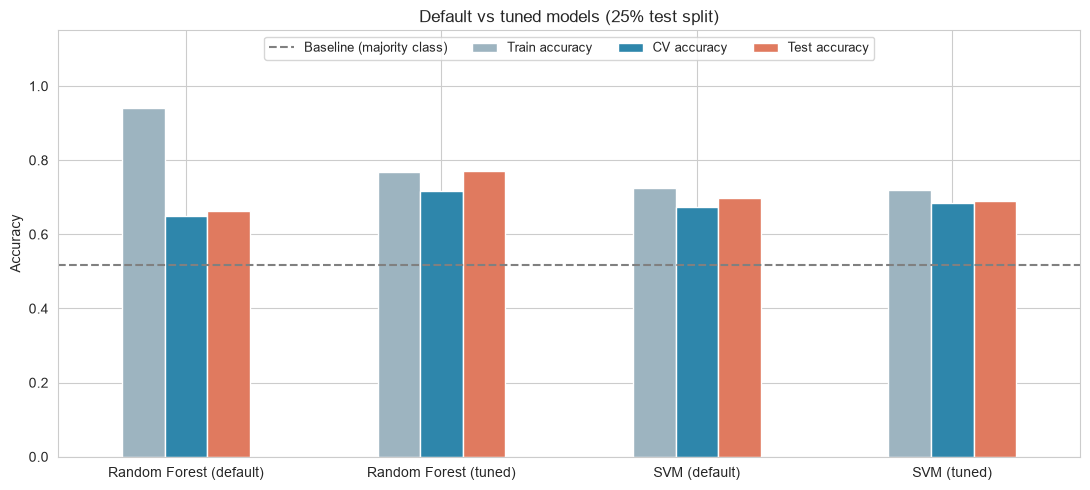

In [17]:
# Chart: train, cross-validation and test accuracy for each model
ax = tuning_df.set_index("Model")[["Train accuracy", "CV accuracy", "Test accuracy"]].plot(
    kind="bar", figsize=(11, 5), color=["#9DB4C0", "#2E86AB", "#E07A5F"])
ax.axhline(baseline, color="grey", linestyle="--", label="Baseline (majority class)")
ax.set_ylim(0, 1.15)
ax.set_ylabel("Accuracy")
ax.set_xlabel("")
ax.set_title("Default vs tuned models (25% test split)")
ax.tick_params(axis="x", rotation=0)
ax.legend(loc="upper center", ncol=4, fontsize=9)
plt.tight_layout()
plt.show()

**Interpretation**
- **Random Forest improved a lot.** The best setting limits the depth of the trees (max_depth = 5) and requires at least 2 records in each leaf (min_samples_leaf = 2). The training accuracy fell from 0.941 to 0.769, while the cross-validation accuracy rose from 0.651 to 0.716 and the test accuracy from 0.664 to 0.770. The gap between training and test accuracy fell from 0.277 to almost zero, so the tuned model **no longer overfits**.
- **SVM changed very little.** The best setting (C = 100, gamma = 0.01) raised the cross-validation accuracy from 0.675 to 0.684, but the test accuracy fell from 0.699 to 0.690, a difference of only one record out of 113. The default SVM was already well balanced.

## 7. Evaluation
### 7.1 Confusion matrices and classification report
In this problem, the most serious error is to classify a **high-risk** pregnancy as low risk, because the woman may not receive the care she needs. For this reason, the recall of the high-risk class is important, not only the overall accuracy.

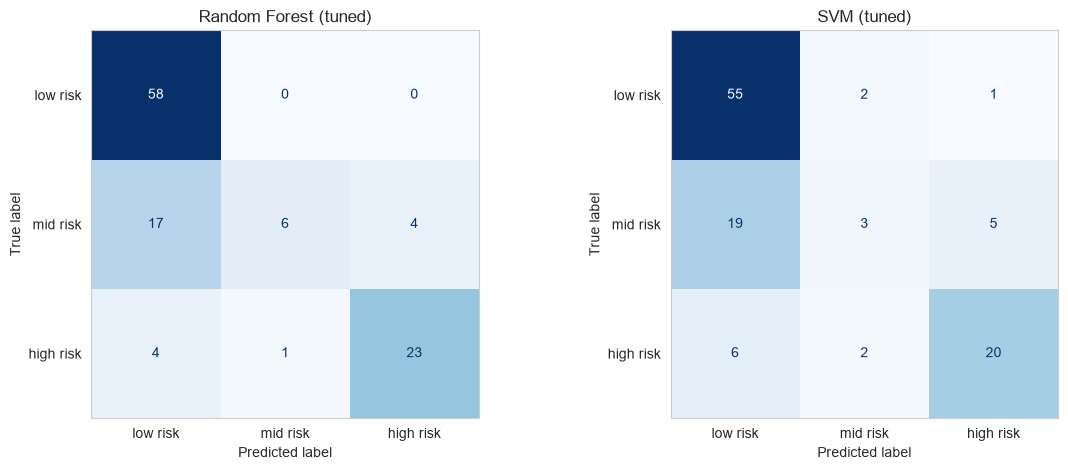

===== Random Forest (tuned) =====
              precision    recall  f1-score   support

    low risk      0.734     1.000     0.847        58
    mid risk      0.857     0.222     0.353        27
   high risk      0.852     0.821     0.836        28

    accuracy                          0.770       113
   macro avg      0.814     0.681     0.679       113
weighted avg      0.793     0.770     0.726       113

===== SVM (tuned) =====
              precision    recall  f1-score   support

    low risk      0.688     0.948     0.797        58
    mid risk      0.429     0.111     0.176        27
   high risk      0.769     0.714     0.741        28

    accuracy                          0.690       113
   macro avg      0.628     0.591     0.571       113
weighted avg      0.646     0.690     0.635       113



In [18]:
# Confusion matrices of the tuned models on the 25% test set
tuned = [("Random Forest (tuned)", rf_search.best_estimator_), ("SVM (tuned)", svm_search.best_estimator_)]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (name, model) in zip(axes, tuned):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=class_names,
                                          cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
    ax.grid(False)   # no grid lines over the matrix
plt.tight_layout()
plt.show()

# Precision, recall and F1-score for each class
for name, model in tuned:
    print(f"===== {name} =====")
    print(classification_report(y_test, model.predict(X_test), target_names=class_names, digits=3))

**Interpretation**
- **Low risk** is almost always recognised (recall 1.000 for Random Forest and 0.948 for SVM).
- **High risk** is recognised well by Random Forest (recall 0.821, precision 0.852): it found 23 of the 28 high-risk women. SVM found 20 of 28 (recall 0.714).
- **Mid risk is the weak point** of both models (recall 0.222 and 0.111). Most mid-risk women were predicted as low risk (17 of 27 for Random Forest). This agrees with the boxplots: low-risk and mid-risk women have very similar values.
- In practice, the model should support a clinical assessment, not replace it, especially for women who are predicted as low risk.

### 7.2 Feature importance and impact on performance

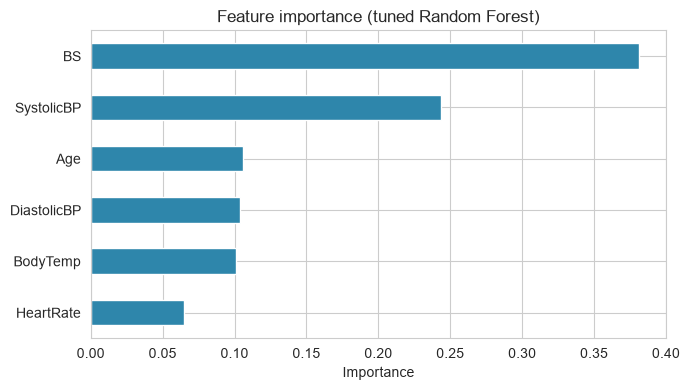

,Removed feature,RF change in CV accuracy,SVM change in CV accuracy
3,BS,-0.086,-0.080
1,SystolicBP,-0.042,-0.030
4,BodyTemp,-0.021,-0.015
0,Age,-0.018,-0.006
2,DiastolicBP,-0.012,-0.006
5,HeartRate,-0.012,-0.009


In [19]:
# Feature importance of the tuned Random Forest
importance = pd.Series(rf_search.best_estimator_.feature_importances_, index=features).sort_values()
importance.plot(kind="barh", color="#2E86AB", figsize=(7, 4))
plt.title("Feature importance (tuned Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

# Impact on performance: change in CV accuracy when one feature is removed
impact = []
for col in features:
    X_drop = X_train.drop(columns=col)
    impact.append({
        "Removed feature": col,
        "RF change in CV accuracy": cv_accuracy(rf_search.best_estimator_, X_drop, y_train) - rf_search.best_score_,
        "SVM change in CV accuracy": cv_accuracy(svm_search.best_estimator_, X_drop, y_train) - svm_search.best_score_,
    })
pd.DataFrame(impact).sort_values("RF change in CV accuracy").round(3)

**Interpretation**
- As in the Kruskal-Wallis test (section 4), **blood sugar (BS)** and **systolic blood pressure** are the two most important features. The other four features have smaller importance (between 0.07 and 0.11).
- When BS is removed, the cross-validation accuracy falls by 8.6 points (Random Forest) and 8.0 points (SVM), which is the largest drop. Systolic blood pressure comes second (4.2 and 3.0 points). Removing any feature lowers the accuracy, so all six features are useful.
- These results make sense clinically: high blood sugar is linked to diabetes in pregnancy, and high blood pressure to pre-eclampsia, one of the main causes of maternal death (WHO, 2025).

### 7.3 Overfitting, underfitting and generalisation

In [20]:
# Records with the same six vital signs but a different risk level (label noise)
labels_per_profile = df_clean.groupby(features)["RiskLevel"].nunique()
conflicting = labels_per_profile[labels_per_profile > 1].index
n_conflict = df_clean.set_index(features).index.isin(conflicting).sum()
print(f"Records with identical features but a different risk level: {n_conflict} "
      f"({n_conflict / len(df_clean):.1%} of the clean data)")

Records with identical features but a different risk level: 71 (15.7% of the clean data)


**Summary**
- **Overfitting:** the default Random Forest overfits (training accuracy 0.941 vs test accuracy 0.664), because deep trees memorise the training data. Tuning (max_depth = 5, min_samples_leaf = 2) removed this gap.
- **Underfitting:** neither model underfits strongly, because both are well above the baseline (0.517). However, the accuracy stays around 0.70–0.77. One reason is **label noise**: 71 records (15.7%) have exactly the same vital signs as another record but a different risk level, so no model can classify all of them correctly.
- **Generalisation:** the tuned Random Forest and both SVM models have small gaps between training, cross-validation and test accuracy, so they should perform in a similar way on new data from the same population. The small dataset and the single region (rural Bangladesh) limit generalisation to other populations.